In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn import tree
df = pd.read_csv("/content/sample_data/Loan_Approval_Dataset.csv")
df.head()

,Income,Credit Score,Loan Amount,Decision
0,45795,691,24360,Denied
1,30860,718,23343,Denied
2,106820,588,10759,Denied
3,84886,678,28078,Approved
4,36265,789,40153,Denied


In [2]:
X = df.drop("Decision", axis=1)
y = df["Decision"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [8]:
"""
for depth in range(1, 11):
  model = DecisionTreeClassifier(criterion="gini", max_depth=depth, random_state=42)
  scores = cross_val_score(model, X, y, cv=5)
  print(f"Depth {depth}: Mean Accuracy = {scores.mean():.3f}")
"""

Depth 1: Mean Accuracy = 0.910
Depth 2: Mean Accuracy = 0.900
Depth 3: Mean Accuracy = 0.940
Depth 4: Mean Accuracy = 0.950
Depth 5: Mean Accuracy = 0.950
Depth 6: Mean Accuracy = 0.950
Depth 7: Mean Accuracy = 0.950
Depth 8: Mean Accuracy = 0.950
Depth 9: Mean Accuracy = 0.950
Depth 10: Mean Accuracy = 0.950


In [9]:
model = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42)

In [10]:
model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

[Text(0.4, 0.875, 'Credit Score <= 665.5\ngini = 0.441\nsamples = 70\nvalue = [23.0, 47.0]\nclass = Reject'),
 Text(0.2, 0.625, 'gini = 0.0\nsamples = 43\nvalue = [0, 43]\nclass = Reject'),
 Text(0.30000000000000004, 0.75, 'True  '),
 Text(0.6, 0.625, 'Income <= 61699.5\ngini = 0.252\nsamples = 27\nvalue = [23, 4]\nclass = Approve'),
 Text(0.5, 0.75, '  False'),
 Text(0.4, 0.375, 'Loan Amount <= 20089.0\ngini = 0.49\nsamples = 7\nvalue = [3, 4]\nclass = Reject'),
 Text(0.2, 0.125, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]\nclass = Approve'),
 Text(0.6, 0.125, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]\nclass = Reject'),
 Text(0.8, 0.375, 'gini = 0.0\nsamples = 20\nvalue = [20, 0]\nclass = Approve')]

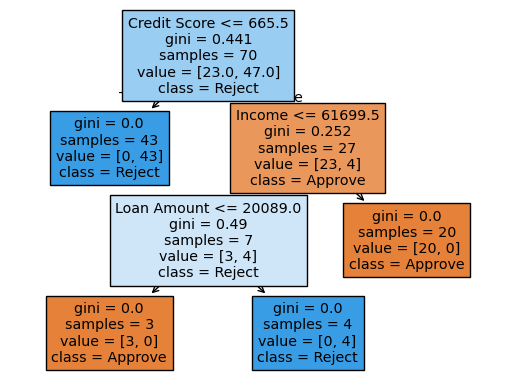

In [12]:
tree.plot_tree(model, feature_names=["Income", "Credit Score", "Loan Amount"], class_names=["Approve", "Reject"], filled=True)

In [19]:
# new applicant
new_applicant = pd.DataFrame({
    "Income": [150000],
    "Credit Score": [340],
    "Loan Amount": [30500]
})

In [20]:
predictions = model.predict(new_applicant)
predictions

array(['Denied'], dtype=object)

In [21]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 93.33%
